## Лабораторная работа 213

Ряд Фурье для периодического сигнала $f(t)$ с периодом $T$ ($\Omega = \frac{2\pi}{T}$):
$$ f(t) = \frac{a_0}{2} + \sum_{n=1}^{\infty} (a_n \cos n\Omega t + b_n \sin n\Omega t) $$
Коэффициенты ряда Фурье:
$$ a_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \cos n\Omega t \, dt \quad (n = 0, 1, 2, \dots) \qquad  b_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \sin n\Omega t \, dt \quad (n = 1, 2, \dots) $$

Амплитуда и фаза $n$-й гармоники:
$$ C_n = \sqrt{a_n^2 + b_n^2}, \qquad \varphi_n = \arctan \frac{a_n}{b_n} \qquad y_n = C_n \sin(\omega_n t + \varphi_n) $$

Комплексная форма ряда Фурье:
$$ f(t) = \sum_{n=-\infty}^{\infty} S_n e^{i n \Omega t}, \qquad S_n = \frac{1}{T} \int_{-T/2}^{T/2} f(t) e^{-i n \Omega t} \, dt, \qquad C_n = 2|S_n| $$

Интеграл Фурье для одиночного импульса ($T \to \infty$):
$$ f(t) = \frac{1}{2\pi} \int_{-\infty}^{\infty} \rho(\omega) e^{i \omega t} \, d\omega, \qquad \rho(\omega) = \int_{-\infty}^{\infty} f(t) e^{-i \omega t} \, dt $$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Часть 1

In [2]:
from dataclasses import dataclass, field

@dataclass(slots=True)
class Envelope: 
    x: np.ndarray = field(default_factory=lambda: np.empty(0))
    y: np.ndarray = field(default_factory=lambda: np.empty(0))

def plot_graph(harmonics: pd.DataFrame, envelope: Envelope, level_e: float | None = None) -> None:
    plt.figure(figsize=(16, 9))
    plt.stem(
        harmonics["freq, kHz"],
        harmonics["A, mV"],
        linefmt="b-",
        markerfmt="bo",
        basefmt=" ",
        # label="Измеренные гармоники (n = 1, 3, 5, 7, 9)",
    )
    plt.plot(
        envelope.x, envelope.y, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
    )
    if level_e is not None:
        plt.axhline(
            level_e,
            color="g",
            linestyle=":",
            label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
        )

    plt.title("Спектр и огибающая прямоугольного сигнала (меандра)")
    plt.xlabel("Частота $\\nu$, кГц")
    plt.ylabel("Амплитуда $A$, мВ")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

##### Квадратный сигнал:

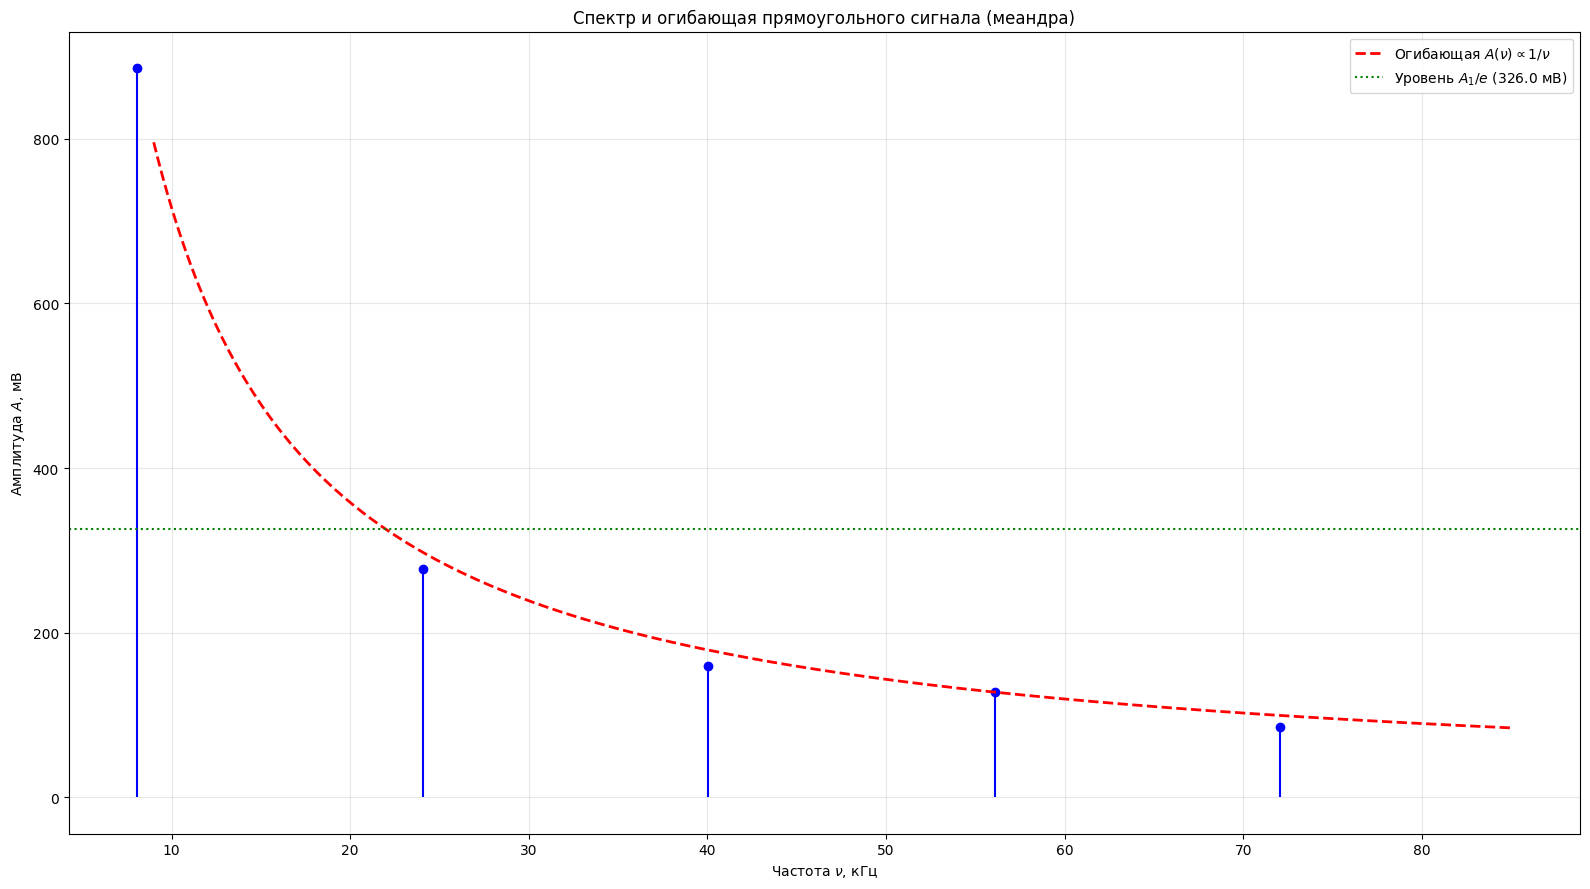

In [3]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084, 24.06, 40.03, 56.08, 72.05],
    "A, mV": [886.1, 277.6, 160.1, 128.1, 85.41],
    "n": [1, 3, 5, 7, 9],
}) # Гармоники
T = (127.3 - 2.732) * 1e-6  # период, с

# Теоретическая огибающая
f_grid = np.linspace(9, 85, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e

plot_graph(harmonics, Envelope(f_grid, envelope), level_e)

#### Синусоида:

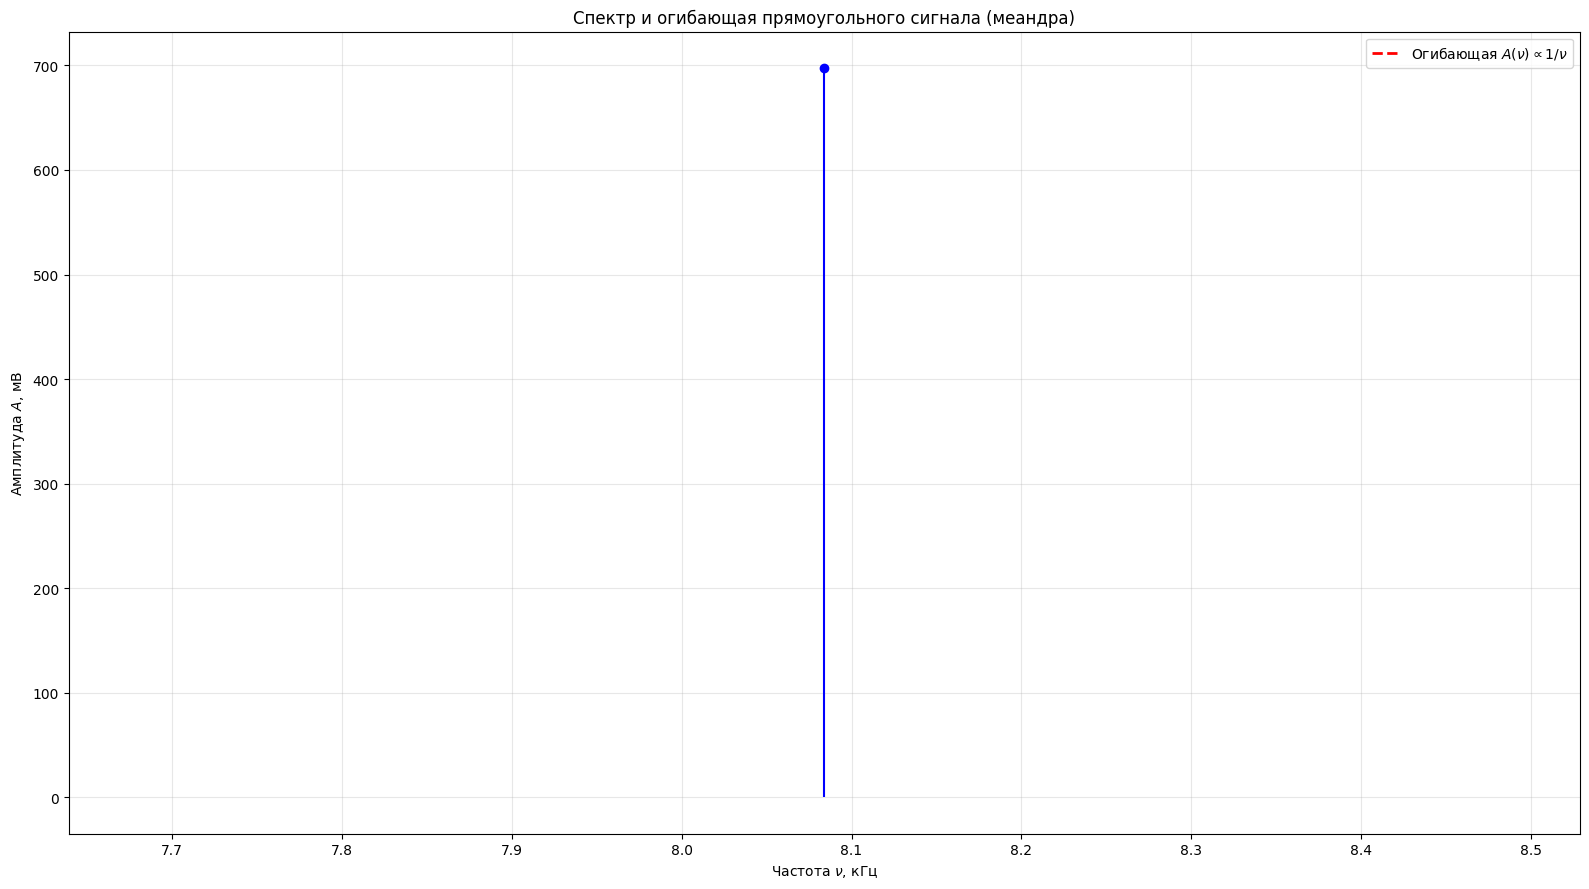

In [5]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084],
    "A, mV": [697.5],
})
T = (156.7 - 31.4) * 1e-6 

plot_graph(harmonics, Envelope())

### Треугольный сигнал

Период T = 125.30 мкс, длительность на полувысоте tau = 62.65 мкс
Ширина спектра (по уровню 1/e): df = 13.08 кГц
Произведение неопределённостей df * tau = 0.82


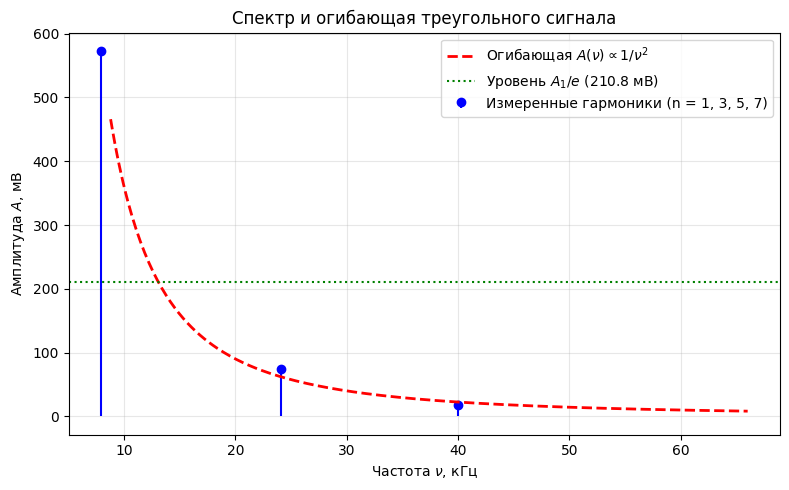

In [6]:
harmonics = pd.DataFrame({
    "freq, kHz": [7.935, 24.13, 39.96],
    "A, mV": [573.0, 74.73, 17.79],
})

T = (156.7 - 31.4) * 1e-6
tau = T / 2  # длительность импульса на полувысоте, с

# Добавлен индекс [0]
f_grid = np.linspace(8.8, 66, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * (f1 / f_grid) ** 2

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.sqrt(np.e)

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# График
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3, 5, 7)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Огибающая $A(\nu) \propto 1/\nu^2$",
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая треугольного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Пилообразный сигнал (повышающийся)

Период T = 124.95 мкс, длительность на полувысоте tau = 62.48 мкс
Ширина спектра (по уровню 1/e): df = 21.97 кГц
Произведение неопределённостей df * tau = 1.37


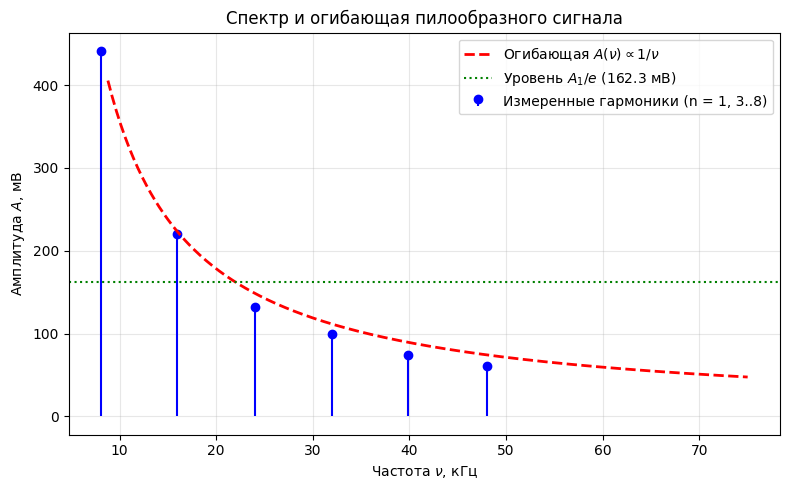

In [7]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084, 15.92, 24.06, 32.04, 39.88, 48.02],
    "A, mV":     [441.3, 220.6, 131.7, 99.64, 74.73, 60.5],
    "n": [1, 2, 3, 4, 5, 6],
})

T = (187.3 - 62.35) * 1e-6 
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"])[0])
A1 = float(np.asarray(harmonics["A, mV"])[0])

f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая пилообразного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Пилообразный сигнал (понижающийся)

Период T = 124.59 мкс, длительность на полувысоте tau = 62.29 мкс
Ширина спектра (по уровню 1/e): df = 21.37 кГц
Произведение неопределённостей df * tau = 1.33


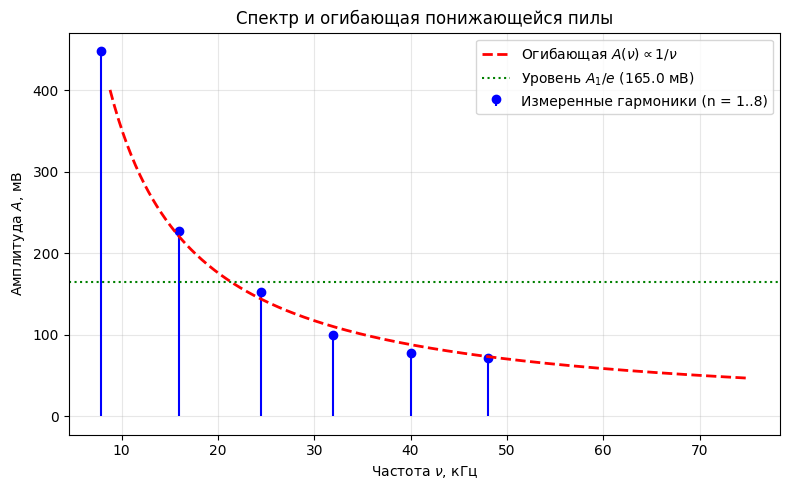

In [8]:
harmonics = pd.DataFrame({
    "freq, kHz": [7.86, 16.0, 24.43, 31.97, 40.03, 48.09],
    "A, mV": [448.4, 227.8, 153.0, 99.64, 78.29, 71.17],
    "n": [1, 2, 3, 4, 5, 6],
})

T = (127.7 - 3.114) * 1e-6 
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))
A1 = float(np.asarray(harmonics["A, mV"]).item(0))

# Теоретическая огибающая A(f) = A1 * f1 / f
f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая понижающейся пилы")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Гаусс:

In [9]:
harmonics = pd.DataFrame({
    "freq, kHz": [0.97, 8.084, 16.7, 23.98],
    "A, mV": [807.8, 637.0, 277.0, 74.73],
    "n": [1, 2, 3, 4]
})

T = (142.6 - 17.25) * 1e-6 